Extracted fake_job_postings.csv from: data\archive.zip
Dataset shape: (17880, 18)

Class distribution:
Real (0): 17014 | Fraud (1): 866 (4.84% fraud)

Missing values (%) per column:


,Missing %
salary_range,83.96
department,64.58
required_education,45.33
benefits,40.34
required_experience,39.43
function,36.10
industry,27.42
employment_type,19.41
company_profile,18.50
requirements,15.08



Fraud rate (%) by has_company_logo:


,Fraud Rate %
has_company_logo,
0,15.93
1,1.99



Fraud rate (%) by employment_type:


,Fraud Rate %
employment_type,
Contract,2.89
Full-time,4.22
Missing,6.94
Other,6.61
Part-time,9.28
Temporary,0.83



Text character length summary by class:


,mean,median,std
fraudulent,,,
0,2700.6,2560.5,1455.8
1,2078.6,1656.5,1529.7


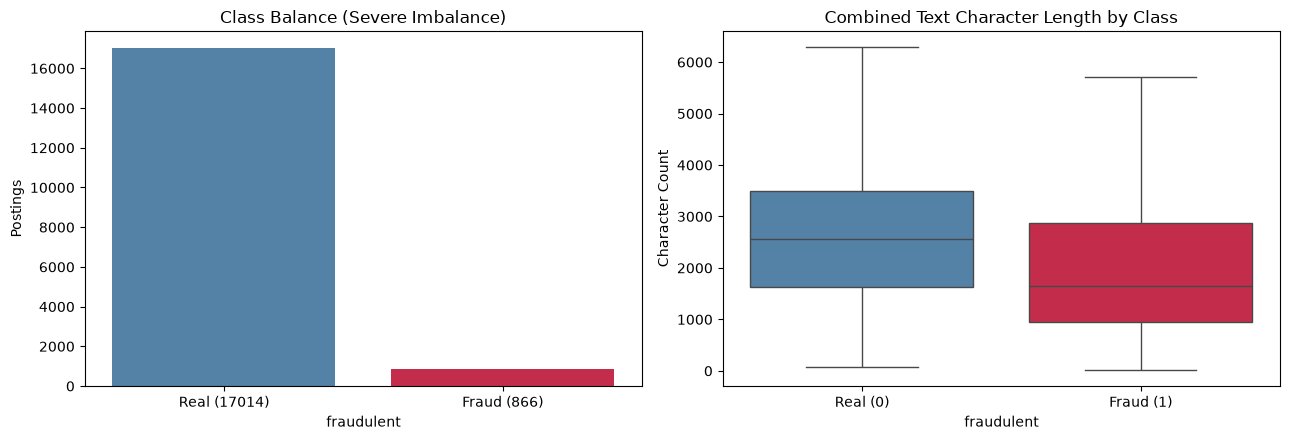

In [2]:
import os
import re
import glob
import shutil
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

target_csv = os.path.join("data", "fake_job_postings.csv")

# Search data/, current folder, Downloads, and Desktop for the CSV or ZIP file
search_dirs = ["data", ".", "..", os.path.expanduser("~/Downloads"), os.path.expanduser("~/Desktop")]

if not os.path.exists(target_csv):
    for folder in search_dirs:
        csv_hits = glob.glob(os.path.join(folder, "fake_job_postings.csv")) + glob.glob(os.path.join(folder, "*", "fake_job_postings.csv"))
        if csv_hits:
            shutil.copy2(csv_hits[0], target_csv)
            print(f"Copied CSV from: {csv_hits[0]}")
            break

if not os.path.exists(target_csv):
    for folder in search_dirs:
        for zpath in sorted(glob.glob(os.path.join(folder, "*.zip")), key=os.path.getmtime, reverse=True):
            try:
                with zipfile.ZipFile(zpath, "r") as zf:
                    matches = [m for m in zf.namelist() if m.endswith("fake_job_postings.csv")]
                    if matches:
                        with zf.open(matches[0]) as src, open(target_csv, "wb") as dst:
                            shutil.copyfileobj(src, dst)
                        print(f"Extracted fake_job_postings.csv from: {zpath}")
                        break
            except Exception:
                pass
        if os.path.exists(target_csv):
            break

if not os.path.exists(target_csv):
    raise FileNotFoundError("Could not find fake_job_postings.csv or its ZIP archive in data/ or Downloads.")

# Load dataset
df = pd.read_csv(target_csv)
print(f"Dataset shape: {df.shape}")

# 1. Class balance
counts = df["fraudulent"].value_counts()
fraud_pct = df["fraudulent"].mean() * 100
print(f"\nClass distribution:\nReal (0): {counts[0]} | Fraud (1): {counts[1]} ({fraud_pct:.2f}% fraud)")

# 2. Missing value percentage per column
missing_pct = (df.isnull().mean() * 100).round(2).sort_values(ascending=False)
print("\nMissing values (%) per column:")
display(missing_pct[missing_pct > 0].to_frame("Missing %"))

# 3. Fraud rate by has_company_logo and employment_type
print("\nFraud rate (%) by has_company_logo:")
display((df.groupby("has_company_logo")["fraudulent"].mean() * 100).round(2).to_frame("Fraud Rate %"))

print("\nFraud rate (%) by employment_type:")
display((df.fillna({"employment_type": "Missing"}).groupby("employment_type")["fraudulent"].mean() * 100).round(2).to_frame("Fraud Rate %"))

# 4. Text length distribution per class
text_cols = ["title", "company_profile", "description", "requirements", "benefits"]
raw_text = df[text_cols].fillna("").agg(" ".join, axis=1)
df["text_char_len"] = raw_text.str.len()

print("\nText character length summary by class:")
display(df.groupby("fraudulent")["text_char_len"].agg(["mean", "median", "std"]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(x="fraudulent", hue="fraudulent", data=df, ax=axes[0], palette=["steelblue", "crimson"], legend=False)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels([f"Real ({counts[0]})", f"Fraud ({counts[1]})"])
axes[0].set_title("Class Balance (Severe Imbalance)")
axes[0].set_ylabel("Postings")

sns.boxplot(x="fraudulent", y="text_char_len", hue="fraudulent", data=df, ax=axes[1], palette=["steelblue", "crimson"], showfliers=False, legend=False)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Real (0)", "Fraud (1)"])
axes[1].set_title("Combined Text Character Length by Class")
axes[1].set_ylabel("Character Count")

plt.tight_layout()
plt.savefig("figures/b1_eda.png", dpi=300)
plt.show()

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

# Clean HTML tags and extra whitespace from combined text
def clean_text(s):
    s = re.sub(r"<[^>]+>", " ", str(s))
    s = re.sub(r"\s+", " ", s).strip()
    return s

text_cols = ["title", "company_profile", "description", "requirements", "benefits"]
df["full_text"] = df[text_cols].fillna("").agg(" ".join, axis=1).apply(clean_text)

# Engineered structured features (row-wise, zero leakage)
df["text_word_count"] = df["full_text"].str.split().str.len()
df["missing_company_profile"] = df["company_profile"].isnull().astype(int)
df["missing_salary_range"] = df["salary_range"].isnull().astype(int)
df["missing_requirements"] = df["requirements"].isnull().astype(int)
df["missing_benefits"] = df["benefits"].isnull().astype(int)

num_cols = [
    "telecommuting", "has_company_logo", "has_questions",
    "text_char_len", "text_word_count",
    "missing_company_profile", "missing_salary_range",
    "missing_requirements", "missing_benefits"
]
cat_cols = ["employment_type", "required_experience", "required_education", "industry", "function"]
for c in cat_cols:
    df[c] = df[c].fillna("Missing")

feature_cols = num_cols + cat_cols + ["full_text"]
X = df[feature_cols]
y = df["fraudulent"]

# Stratified 70 / 15 / 15 split
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)
print(f"Split sizes -> Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")

# Preprocessors fitted ONLY on X_train
structured_transformer = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", max_categories=20), cat_cols)
])

text_transformer = ColumnTransformer([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=20000, stop_words="english", sublinear_tf=True), "full_text")
])

combined_preprocessor = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", max_categories=20), cat_cols),
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), max_features=20000, stop_words="english", sublinear_tf=True), "full_text")
])

X_train_comb = combined_preprocessor.fit_transform(X_train)
X_val_comb = combined_preprocessor.transform(X_val)
X_test_comb = combined_preprocessor.transform(X_test)
vocab_size = len(combined_preprocessor.named_transformers_["tfidf"].vocabulary_)
print(f"Combined feature matrix shape (Train): {X_train_comb.shape} | TF-IDF Vocab Size: {vocab_size}")

Split sizes -> Train: 12516 | Val: 2682 | Test: 2682
Combined feature matrix shape (Train): (12516, 20077) | TF-IDF Vocab Size: 20000


,Model,Val Threshold,Precision (Fraud),Recall (Fraud),F1 (Fraud),PR-AUC,ROC-AUC
0,Logistic Regression,0.76,0.8607,0.8077,0.8333,0.9080,0.9917
1,Linear SVM (Calibrated),0.40,0.9138,0.8154,0.8618,0.9404,0.9925
2,Random Forest,0.66,0.9140,0.6538,0.7623,0.8399,0.9834



Best Model: Linear SVM (Calibrated)
Confusion Matrix (TN, FP, FN, TP): [2542, 10, 24, 106]


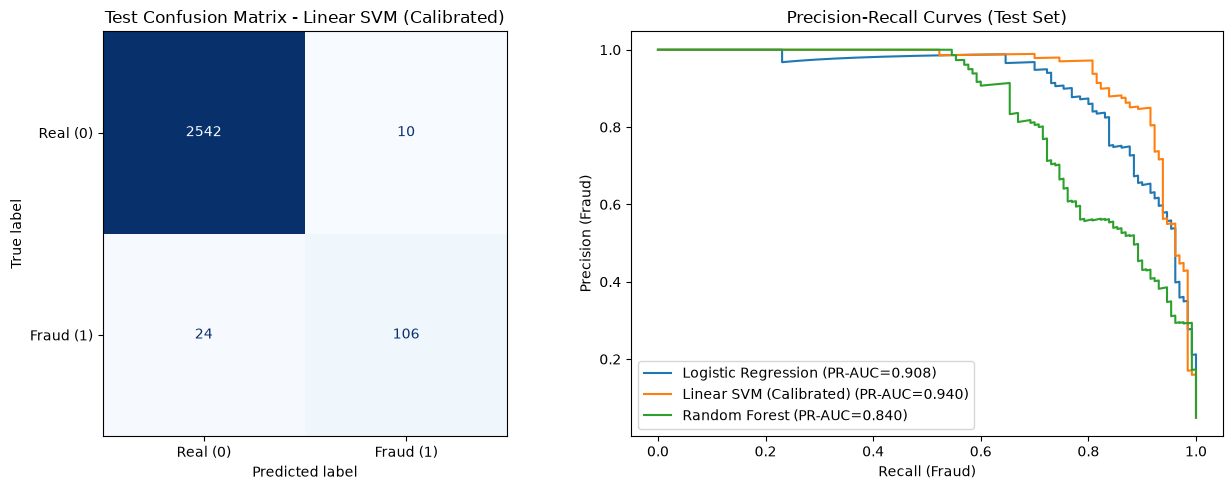

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score, average_precision_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve
)

models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", C=1.0, max_iter=1000, random_state=RANDOM_STATE),
    "Linear SVM (Calibrated)": CalibratedClassifierCV(LinearSVC(class_weight="balanced", C=0.5, random_state=RANDOM_STATE), cv=3),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=25, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
}

def find_best_threshold(y_true, probs):
    best_t, best_f1 = 0.50, 0.0
    for t in np.arange(0.10, 0.91, 0.02):
        score = f1_score(y_true, (probs >= t).astype(int), zero_division=0)
        if score > best_f1:
            best_f1 = score
            best_t = round(float(t), 2)
    return best_t

trained_models = {}
best_thresholds = {}
test_rows = []

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, clf in models.items():
    clf.fit(X_train_comb, y_train)
    trained_models[name] = clf
    
    # Tune threshold on validation set ONLY
    val_probs = clf.predict_proba(X_val_comb)[:, 1]
    t_opt = find_best_threshold(y_val, val_probs)
    best_thresholds[name] = t_opt
    
    # Evaluate once on test set
    test_probs = clf.predict_proba(X_test_comb)[:, 1]
    test_preds = (test_probs >= t_opt).astype(int)
    
    pr_auc = average_precision_score(y_test, test_probs)
    roc_auc = roc_auc_score(y_test, test_probs)
    
    test_rows.append({
        "Model": name,
        "Val Threshold": t_opt,
        "Precision (Fraud)": round(precision_score(y_test, test_preds), 4),
        "Recall (Fraud)": round(recall_score(y_test, test_preds), 4),
        "F1 (Fraud)": round(f1_score(y_test, test_preds), 4),
        "PR-AUC": round(pr_auc, 4),
        "ROC-AUC": round(roc_auc, 4)
    })
    
    prec_curve, rec_curve, _ = precision_recall_curve(y_test, test_probs)
    axes[1].plot(rec_curve, prec_curve, label=f"{name} (PR-AUC={pr_auc:.3f})")

results_df = pd.DataFrame(test_rows)
display(results_df)

best_model_name = results_df.sort_values(by=["F1 (Fraud)", "PR-AUC"], ascending=False).iloc[0]["Model"]
print(f"\nBest Model: {best_model_name}")

# Confusion matrix for best model
best_test_probs = trained_models[best_model_name].predict_proba(X_test_comb)[:, 1]
best_test_preds = (best_test_probs >= best_thresholds[best_model_name]).astype(int)
cm = confusion_matrix(y_test, best_test_preds)
print(f"Confusion Matrix (TN, FP, FN, TP): {cm.ravel().tolist()}")

ConfusionMatrixDisplay(cm, display_labels=["Real (0)", "Fraud (1)"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Test Confusion Matrix - {best_model_name}")

axes[1].set_title("Precision-Recall Curves (Test Set)")
axes[1].set_xlabel("Recall (Fraud)")
axes[1].set_ylabel("Precision (Fraud)")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/b1_results.png", dpi=300)
plt.show()

In [5]:
from sklearn.base import clone

ablation_configs = {
    "Structured Only": structured_transformer,
    "Text Only": text_transformer,
    "Combined (Structured + Text)": combined_preprocessor
}

ablation_rows = []
base_clf = models[best_model_name]

for setting, prep in ablation_configs.items():
    X_tr = prep.fit_transform(X_train)
    X_va = prep.transform(X_val)
    X_te = prep.transform(X_test)
    
    clf = clone(base_clf)
    clf.fit(X_tr, y_train)
    
    t_opt = find_best_threshold(y_val, clf.predict_proba(X_va)[:, 1])
    te_probs = clf.predict_proba(X_te)[:, 1]
    te_preds = (te_probs >= t_opt).astype(int)
    
    ablation_rows.append({
        "Feature Set": setting,
        "Num Features": X_tr.shape[1],
        "Threshold": t_opt,
        "Precision (Fraud)": round(precision_score(y_test, te_preds), 4),
        "Recall (Fraud)": round(recall_score(y_test, te_preds), 4),
        "F1 (Fraud)": round(f1_score(y_test, te_preds), 4),
        "PR-AUC": round(average_precision_score(y_test, te_probs), 4),
        "ROC-AUC": round(roc_auc_score(y_test, te_probs), 4)
    })

ablation_df = pd.DataFrame(ablation_rows)
print(f"Ablation Study using {best_model_name}:")
display(ablation_df)

Ablation Study using Linear SVM (Calibrated):


,Feature Set,Num Features,Threshold,Precision (Fraud),Recall (Fraud),F1 (Fraud),PR-AUC,ROC-AUC
0,Structured Only,77,0.14,0.3091,0.6538,0.4198,0.3639,0.9065
1,Text Only,20000,0.28,0.8271,0.8462,0.8365,0.9244,0.9895
2,Combined (Structured + Text),20077,0.40,0.9138,0.8154,0.8618,0.9404,0.9925
